# World Happiness Analysis
### Evaluasi hidup lintas negara berdasarkan World Happiness Report 2026

**Surya Winaldi Yakin · Portofolio Data Analyst**

Notebook ini meninjau distribusi skor 2023–2025, membandingkan perubahan dengan cakupan negara yang konsisten, dan mengaudit dekomposisi skor WHR. Unit analisisnya negara atau teritori per label tahun. Label 2025 mewakili jendela 2023–2025. Seri historis berisi skor tiga tahunan dan melewatkan label 2013.

**Cara menjalankan di Colab.** Unggah notebook ini, pilih **Runtime → Run all**, lalu lihat tabel dan grafik di folder `outputs/` dan `visuals/`. Sel pertama mencari workbook lokal atau mengunduh workbook resmi dan memeriksa SHA-256. Pada eksekusi lokal jalankan dari akar proyek. 

[Sumber resmi](https://www.worldhappiness.report/ed/2026/) · [Data sharing](https://www.worldhappiness.report/data-sharing/) · [Workbook Figure 2.1](https://files.worldhappiness.report/WHR26_Data_Figure_2.1.xlsx) · [Lampiran statistik](https://files.worldhappiness.report/WHR26_Statistical_Appendix.pdf)

In [1]:
from hashlib import sha256
from io import BytesIO
from pathlib import Path
from urllib.error import URLError
from urllib.request import Request, urlopen
import json
import sys

from IPython.display import display, Image
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd

pd.options.display.float_format = '{:.3f}'.format
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'font.size': 10,
                     'axes.labelcolor': '#233349', 'text.color': '#233349'})

FILE = 'WHR26_Data_Figure_2.1.xlsx'
URL = f'https://files.worldhappiness.report/{FILE}'
SHEET = 'Data for Figure 2.1 (2011–2025)'
EXPECTED_HASH = '576e382655cec3ae704a0b41cd2c04465b87cd84b7f131a0c4fa26d41f6d8028'
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
local_candidates = (ROOT / 'data' / 'raw' / FILE, ROOT / FILE)
local_workbook = next((path for path in local_candidates if path.is_file()), None)
if local_workbook is None:
    try:
        request = Request(URL, headers={'User-Agent': 'Mozilla/5.0'})
        with urlopen(request, timeout=45) as response:
            snapshot = response.read()
    except (URLError, TimeoutError) as error:
        raise RuntimeError(f'Unduh {URL}, unggah {FILE} ke folder kerja, lalu jalankan kembali.') from error
else:
    snapshot = local_workbook.read_bytes()
if sha256(snapshot).hexdigest() != EXPECTED_HASH:
    raise ValueError('Workbook berbeda dari edisi yang divalidasi. Periksa sumber dan versi file.')

raw = pd.read_excel(BytesIO(snapshot), sheet_name=SHEET, engine='openpyxl')
OUT, VIS = ROOT / 'outputs', ROOT / 'visuals'
OUT.mkdir(exist_ok=True)
VIS.mkdir(exist_ok=True)
print(f'Input: {local_workbook.relative_to(ROOT) if local_workbook else URL}')
print(f'SHA-256 workbook resmi: {EXPECTED_HASH}')
print(f'Python {sys.version.split()[0]} · pandas {pd.__version__} · NumPy {np.__version__} · Matplotlib {matplotlib.__version__}')

Input: https://files.worldhappiness.report/WHR26_Data_Figure_2.1.xlsx
SHA-256 workbook resmi: 576e382655cec3ae704a0b41cd2c04465b87cd84b7f131a0c4fa26d41f6d8028
Python 3.12.14 · pandas 2.2.3 · NumPy 2.3.5 · Matplotlib 3.10.8


## 1. Pembersihan dan pemeriksaan kualitas

Workbook resmi dibaca dengan presisi yang tersedia. Nama negara mengikuti sumber. Nilai yang hilang dipertahankan sebagai NA dan dipisahkan dari kontribusi nol. Skor, peringkat, batas interval, cakupan label, dan konsistensi kunci diperiksa sebelum analisis.

In [2]:
column_map = {
    'Year': 'year', 'Rank': 'rank', 'Country name': 'country',
    'Life evaluation (3-year average)': 'score',
    'Lower whisker': 'ci_lower', 'Upper whisker': 'ci_upper',
    'Explained by: Log GDP per capita': 'c_gdp',
    'Explained by: Social support': 'c_support',
    'Explained by: Healthy life expectancy': 'c_health',
    'Explained by: Freedom to make life choices': 'c_freedom',
    'Explained by: Generosity': 'c_generosity',
    'Explained by: Perceptions of corruption': 'c_corruption',
    'Dystopia + residual': 'dystopia_residual',
}
COMP = list(column_map.values())[6:]
LABELS = ['PDB per kapita', 'Dukungan sosial', 'Harapan hidup sehat',
          'Kebebasan memilih', 'Kedermawanan', 'Persepsi korupsi', 'Dystopia + residual']
data = raw.rename(columns=column_map)
assert list(data.columns) == list(column_map.values())
data['country'] = data['country'].astype('string').str.strip()
numeric = data.columns.drop('country')
data[numeric] = data[numeric].apply(pd.to_numeric, errors='raise')
data = data.sort_values(['year', 'rank']).reset_index(drop=True)
assert data['country'].notna().all() and data['country'].ne('').all()
assert not data.duplicated(['country', 'year']).any()
assert data['score'].between(0, 10).all()
assert data['rank'].ge(1).all()
rank_checks = data[['year', 'rank', 'country', 'score']].assign(
    previous_rank_score=data.groupby('year')['score'].shift(),
    duplicate_rank=data.duplicated(['year', 'rank'], keep=False))
rank_gaps = pd.DataFrame([(year, rank) for year, group in data.groupby('year')
                          for rank in sorted(set(range(1, len(group) + 1)) - set(group['rank']))],
                         columns=['year', 'missing_rank'])
rank_gaps.to_csv(OUT / 'rank_gaps.csv', index=False)
rank_exceptions = rank_checks.loc[
    rank_checks.score.gt(rank_checks.previous_rank_score) | rank_checks.duplicate_rank]
rank_exceptions.to_csv(OUT / 'rank_order_exceptions.csv', index=False)
assert not rank_exceptions.year.eq(2025).any()
assert data.loc[data.year.eq(2025), 'rank'].tolist() == list(range(1, 148))
display(rank_exceptions)
has_ci = data['ci_lower'].notna()
assert has_ci.equals(data['ci_upper'].notna())
assert ((data.loc[has_ci, 'ci_lower'] <= data.loc[has_ci, 'score']) &
        (data.loc[has_ci, 'score'] <= data.loc[has_ci, 'ci_upper'])).all()
data['complete_decomposition'] = data[COMP].notna().all(axis=1)
years = sorted(data['year'].unique())
assert years == [2011, 2012, *range(2014, 2026)]
assert (len(data), data['country'].nunique()) == (2116, 168)
coverage = data.assign(has_ci=has_ci).groupby('year').agg(
    countries=('country', 'size'), intervals=('has_ci', 'sum'),
    complete_decomposition=('complete_decomposition', 'sum'))
coverage.to_csv(OUT / 'coverage.csv')
data.to_csv(OUT / 'happiness_clean.csv', index=False)
data.groupby('year')[['ci_lower', 'ci_upper', *COMP]].agg(lambda x: x.isna().sum()).to_csv(
    OUT / 'missing_by_year.csv')
display(coverage)

,year,rank,country,score,previous_rank_score,duplicate_rank
1057,2018,120,Gambia,4.516,4.519,True
1058,2018,120,Sri Lanka,4.366,4.516,True
1059,2018,121,Kenya,4.509,4.366,False


,countries,intervals,complete_decomposition
year,,,
2011,156,0,0
2012,156,0,0
2014,158,0,0
2015,157,0,0
2016,155,0,0
2017,156,0,0
2018,156,0,0
2019,153,153,153
2020,149,149,149


## 2. Potret 2023–2025

Distribusi memberi bobot yang sama untuk setiap negara yang tercakup. Peringkat menggunakan urutan publikasi. Whisker merupakan interval kepercayaan (IK) 95% untuk skor masing-masing negara. Uji beda antarnegara memerlukan galat selisih. Tumpang tindih IK skor tidak cukup untuk menyatakan dua negara setara.

,value
n,147.000
mean,5.650
median,5.937
sd,1.138
q1,4.666
q3,6.576
skew,-0.609
min,1.446
max,7.764
range,6.318


,rank,country,score,ci_lower,ci_upper
1970,2,Iceland,7.540,7.449,7.630
1971,3,Denmark,7.539,7.446,7.631
2055,87,Indonesia,5.617,5.517,5.718


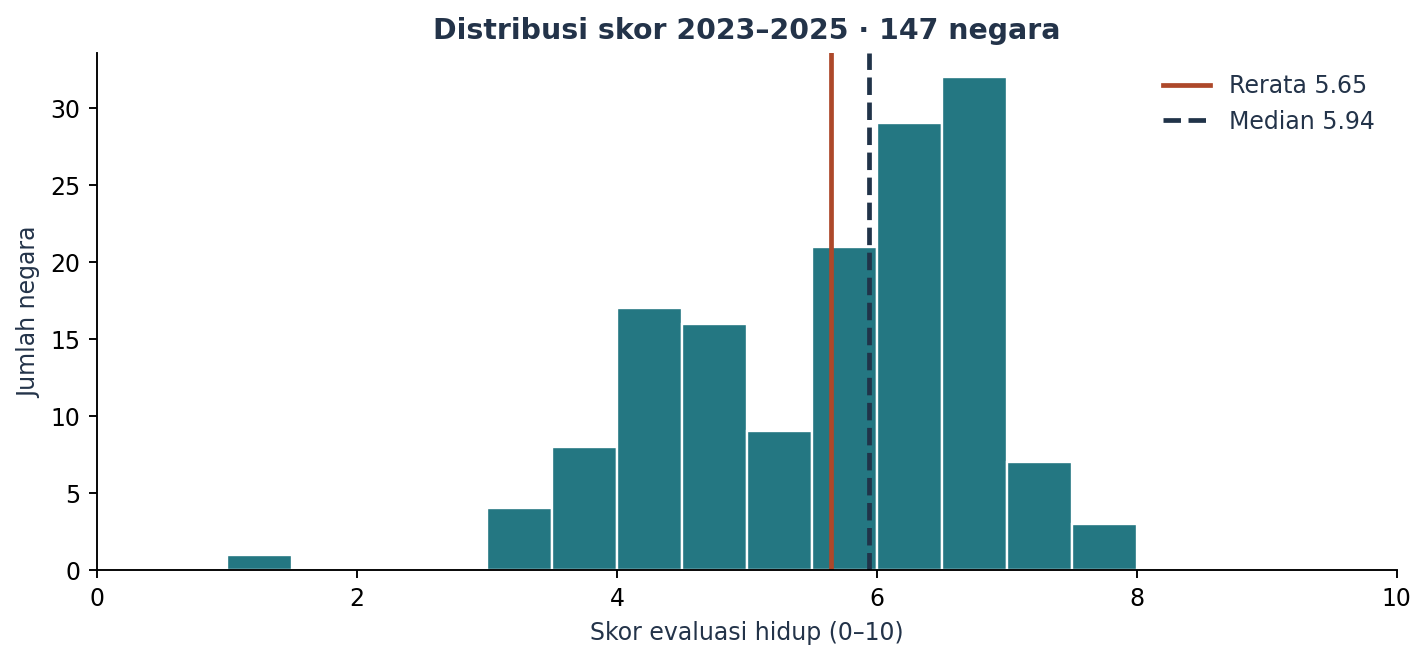

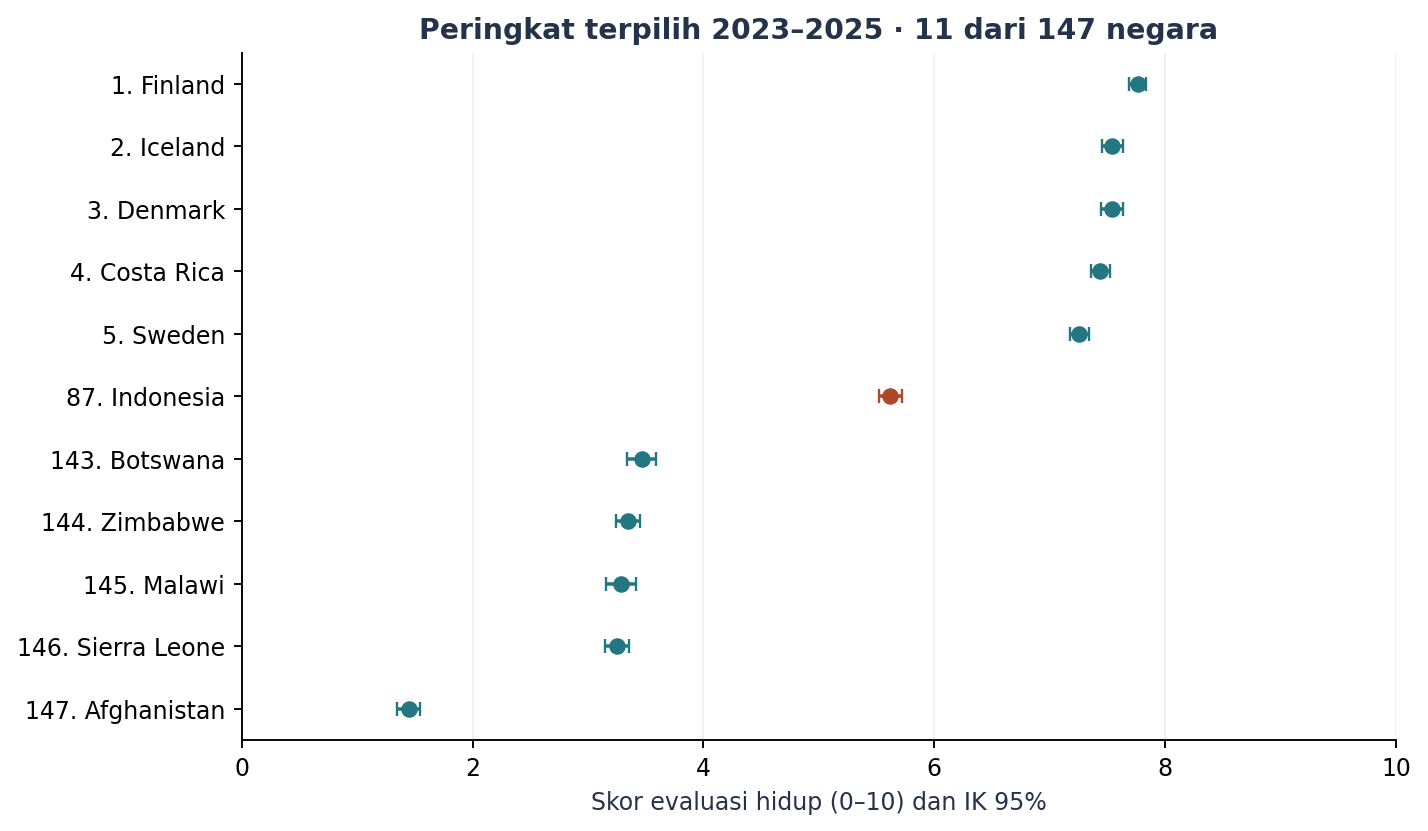

In [3]:
def publish(fig, filename):
    path = VIS / filename
    fig.tight_layout()
    fig.savefig(path, dpi=170, bbox_inches='tight', facecolor='white')
    plt.close(fig)
    display(Image(filename=str(path)))

latest = data.loc[data.year.eq(2025)].copy()
assert len(latest) == 147
s = latest.score
snapshot_summary = {'n': len(s), 'mean': s.mean(), 'median': s.median(), 'sd': s.std(),
                    'q1': s.quantile(.25), 'q3': s.quantile(.75), 'skew': s.skew(),
                    'min': s.min(), 'max': s.max(), 'range': s.max()-s.min()}
pd.Series(snapshot_summary, name='value').to_csv(OUT / 'snapshot_summary.csv')
latest[['rank', 'country', 'score', 'ci_lower', 'ci_upper']].to_csv(
    OUT / 'ranking_2023_2025.csv', index=False)
reference = latest[latest.country.isin(['Indonesia', 'Iceland', 'Denmark'])]
display(pd.Series(snapshot_summary, name='value').to_frame())
display(reference[['rank', 'country', 'score', 'ci_lower', 'ci_upper']])

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.hist(s, bins=np.arange(0, 10.5, .5), color='#247782', edgecolor='white')
ax.axvline(s.mean(), color='#ad482a', label=f'Rerata {s.mean():.2f}', lw=2)
ax.axvline(s.median(), color='#203349', label=f'Median {s.median():.2f}', ls='--', lw=2)
ax.set(xlim=(0, 10), xlabel='Skor evaluasi hidup (0–10)', ylabel='Jumlah negara',
       title=f'Distribusi skor 2023–2025 · {len(latest)} negara')
ax.legend(frameon=False)
publish(fig, '01_distribution.png')

focus = pd.concat([latest.head(5), latest[latest.country.eq('Indonesia')], latest.tail(5)])
fig, ax = plt.subplots(figsize=(8.5, 5))
for row in focus.itertuples():
    color = '#ad482a' if row.country == 'Indonesia' else '#247782'
    ax.errorbar(row.score, f'{row.rank}. {row.country}', color=color, fmt='o', capsize=3,
                xerr=[[row.score-row.ci_lower], [row.ci_upper-row.score]])
ax.invert_yaxis()
ax.set(xlim=(0, 10), xlabel='Skor evaluasi hidup (0–10) dan IK 95%',
       title='Peringkat terpilih 2023–2025 · 11 dari 147 negara')
ax.grid(axis='x', alpha=.18)
publish(fig, '02_ranking_intervals.png')

## 3. Perubahan dan sensitivitas cakupan

Bandingkan tiga ringkasan. Panel tersedia mengikuti daftar negara tiap label. Panel seimbang menggunakan negara dengan seluruh 14 label. Panel berpasangan menggunakan negara yang tersedia pada setiap pasangan periode yang dibandingkan. Panel seimbang menahan komposisi, tetapi dapat menyeleksi negara dengan survei yang lebih konsisten.

Perbandingan utama memakai 2017–2019 dan 2023–2025. Jendela tersebut terpisah secara kalender dan keduanya punya data skor serta interval nasional. Perbandingan 2020–2022 ke 2023–2025 dan 2011 ke 2025 menjadi sensitivitas. Perubahan didefinisikan sebagai skor akhir dikurangi skor awal. Ekstrem dan arah perubahan dihitung pada presisi workbook.

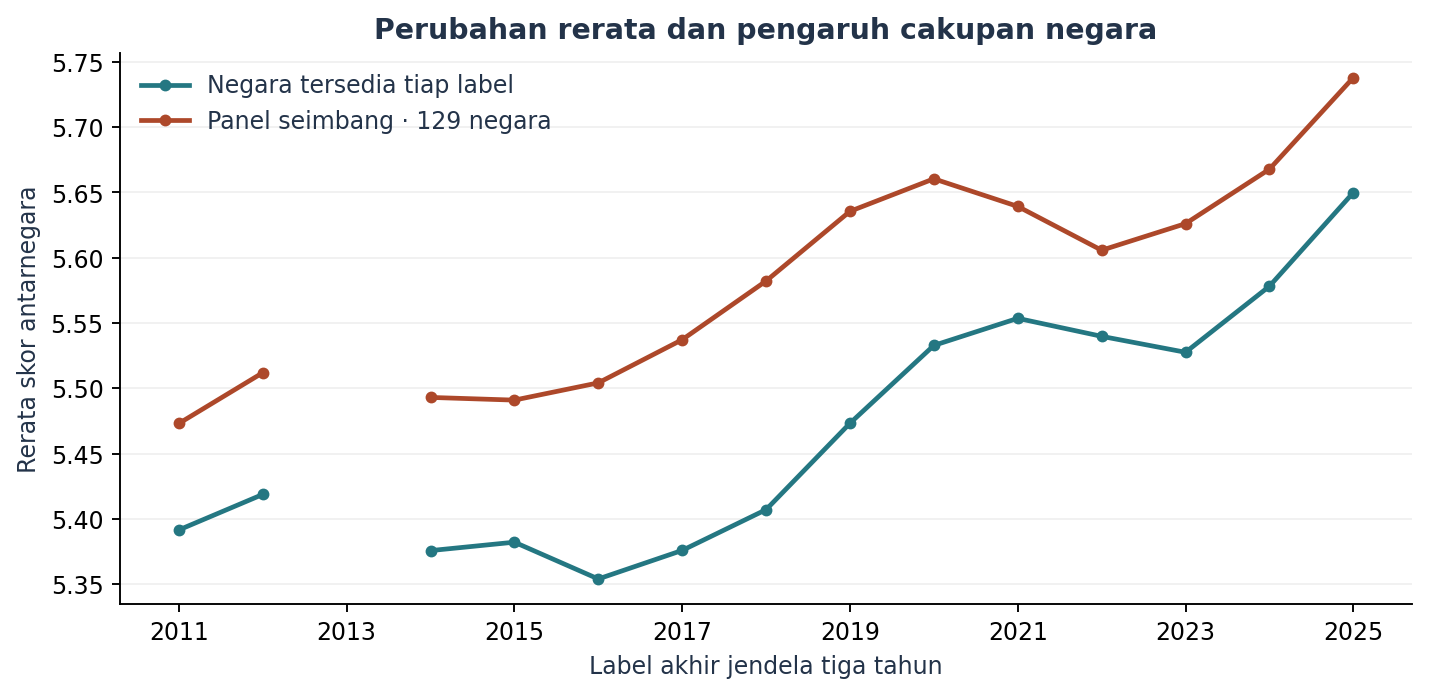

,available_n,available_mean,balanced_n,balanced_mean
year,,,,
2011,156,5.392,129,5.473
2012,156,5.419,129,5.512
2014,158,5.376,129,5.493
2015,157,5.382,129,5.491
2016,155,5.354,129,5.504
2017,156,5.376,129,5.537
2018,156,5.407,129,5.582
2019,153,5.473,129,5.636
2020,149,5.533,129,5.660


,n,mean_delta,median_delta,trimmed_mean_10pct,q1_delta,q3_delta,increased,decreased,same_at_precision
comparison,,,,,,,,,
2011–2025 matched,141,0.255,0.232,0.266,-0.187,0.702,89,52,0
2011–2025 balanced,129,0.265,0.232,0.279,-0.187,0.716,82,47,0
2019–2025 matched,143,0.102,0.091,0.110,-0.159,0.408,90,53,0
2019–2025 balanced,129,0.102,0.091,0.112,-0.141,0.406,82,47,0
2022–2025 matched,137,0.140,0.113,0.133,-0.059,0.380,91,46,0
2022–2025 balanced,129,0.132,0.104,0.124,-0.073,0.354,83,46,0


year,start_score,end_score,delta
country,,,
Viet Nam,5.353,6.428,1.075
India,3.573,4.536,0.963
China,5.124,6.074,0.950
Serbia,5.778,6.691,0.913
Armenia,4.677,5.584,0.907
Indonesia,5.286,5.617,0.331
Congo,5.194,4.456,-0.738
Benin,5.216,4.393,-0.823
Pakistan,5.693,4.868,-0.825


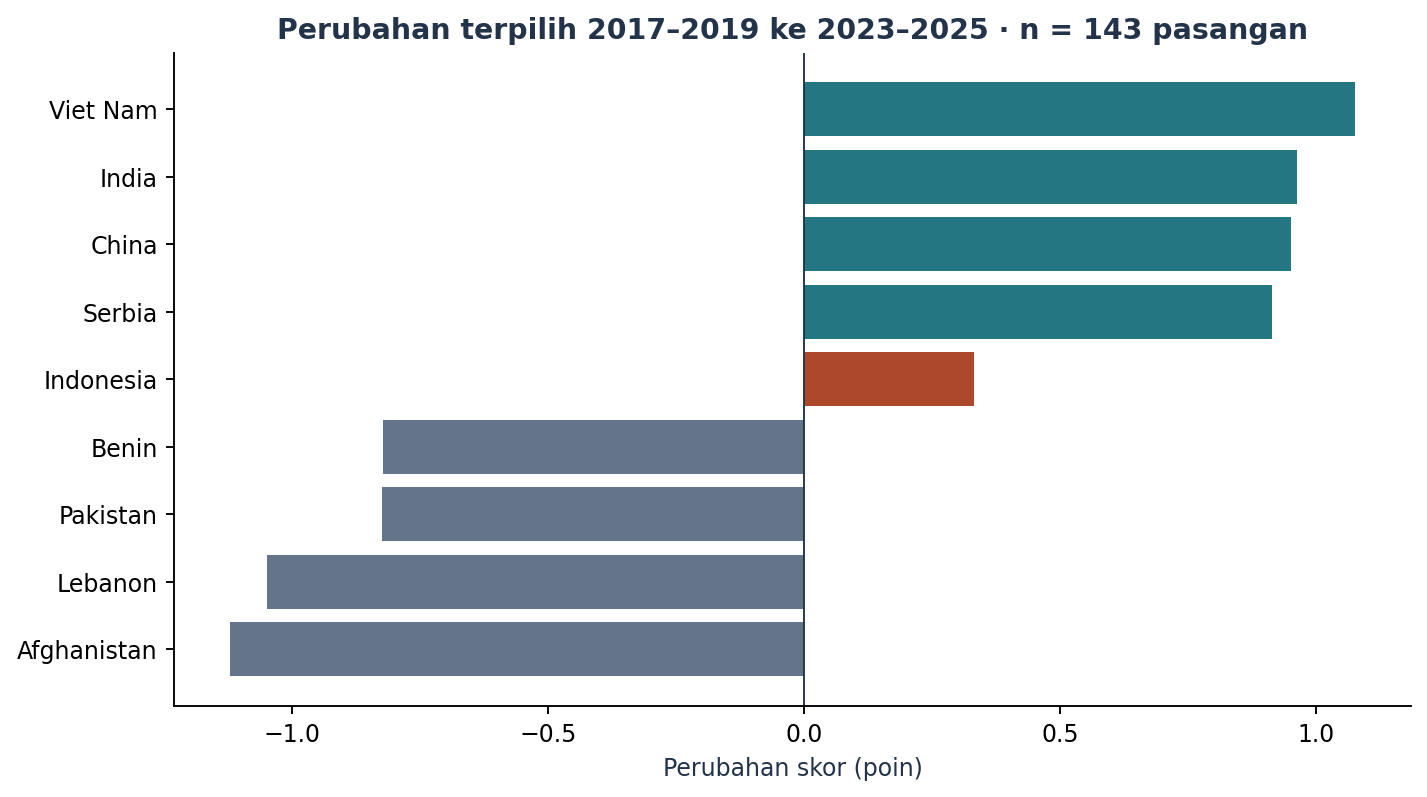

In [4]:
wide = data.pivot(index='country', columns='year', values='score')
balanced = wide.dropna()
trend = pd.DataFrame({
    'available_n': wide.count(), 'available_mean': wide.mean(),
    'balanced_n': len(balanced), 'balanced_mean': balanced.mean()
})
trend.index.name = 'year'
trend.to_csv(OUT / 'panel_trends.csv')

fig, ax = plt.subplots(figsize=(8.5, 4.2))
for col, name, color in [
    ('available_mean', 'Negara tersedia tiap label', '#247782'),
    ('balanced_mean', f'Panel seimbang · {len(balanced)} negara', '#ad482a'),
]:
    line = trend[col].reindex(range(2011, 2026))
    ax.plot(line.index, line, 'o-', color=color, label=name, lw=2, ms=4)
ax.set(xticks=[2011, 2013, 2015, 2017, 2019, 2021, 2023, 2025],
       ylabel='Rerata skor antarnegara', xlabel='Label akhir jendela tiga tahun',
       title='Perubahan rerata dan pengaruh cakupan negara')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=.18)
publish(fig, '03_panel_trends.png')
display(trend)

def compare(start, end):
    pair = wide[[start, end]].dropna().rename(columns={start: 'start_score', end: 'end_score'})
    return pair.assign(delta=(pair.end_score - pair.start_score).round(10)).sort_values(
        'delta', ascending=False, kind='stable')

def change_stats(pair):
    d = pair.delta.sort_values()
    trim = int(.10 * len(d))
    return {'n': len(d), 'mean_delta': d.mean(), 'median_delta': d.median(),
            'trimmed_mean_10pct': d.iloc[trim:len(d)-trim].mean(),
            'q1_delta': d.quantile(.25), 'q3_delta': d.quantile(.75),
            'increased': int(d.gt(0).sum()), 'decreased': int(d.lt(0).sum()),
            'same_at_precision': int(d.eq(0).sum())}

main = compare(2019, 2025)
main.to_csv(OUT / 'country_changes_2019_2025.csv')
comparisons = {}
for start in [2011, 2019, 2022]:
    pair = compare(start, 2025)
    comparisons[f'{start}–2025 matched'] = change_stats(pair)
    comparisons[f'{start}–2025 balanced'] = change_stats(pair.loc[balanced.index])
change_summary = pd.DataFrame.from_dict(comparisons, orient='index').rename_axis('comparison')
change_summary.to_csv(OUT / 'change_sensitivity.csv')
display(change_summary)
display(pd.concat([main.head(5), main.loc[['Indonesia']], main.tail(5)]))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
shown = pd.concat([main.head(4), main.loc[['Indonesia']], main.tail(4)]).sort_values('delta')
colors = ['#ad482a' if name == 'Indonesia' else '#247782' if value > 0 else '#64748b'
          for name, value in shown.delta.items()]
ax.barh(shown.index, shown.delta, color=colors)
ax.axvline(0, color='#233349', lw=.8)
ax.set(xlabel='Perubahan skor (poin)',
       title=f'Perubahan terpilih 2017–2019 ke 2023–2025 · n = {len(main)} pasangan')
publish(fig, '04_country_changes.png')

## 4. Pemeriksaan asumsi dan interpretasi statistik

- **Independensi waktu.** Jendela tiga tahun dengan label berjarak satu tahun berbagi dua tahun kalender. Korelasi lag dihitung hanya untuk label yang benar-benar berjarak satu tahun dan digunakan sebagai diagnosis, dengan pasangan yang saling berbagi titik serta seri pendek. Korelasi tersebut juga dapat mencerminkan tren.
- **Pengaruh ekstrem dan bentuk distribusi.** Rerata, median, rerata pangkas 10% per ekor, kuartil, dan hitungan arah perubahan dipakai bersama. Plot Q–Q membantu melihat penyimpangan terhadap normalitas pada perubahan berpasangan. Tidak ada keharusan normalitas bagi ringkasan deskriptif ini.
- **Kemandirian antarnegara dan galat survei.** Negara dapat berbagi guncangan regional, dan desain survei atau kovarians galat lengkap tidak tersedia di tabel. Analisis menggunakan IK resmi untuk skor dan melaporkan perubahan sebagai estimasi titik, tanpa uji t lintas negara atau interval perubahan dari selisih whisker.

,adjacent_pairs,lag1_r
available_mean,12.000,0.939
balanced_mean,12.000,0.917


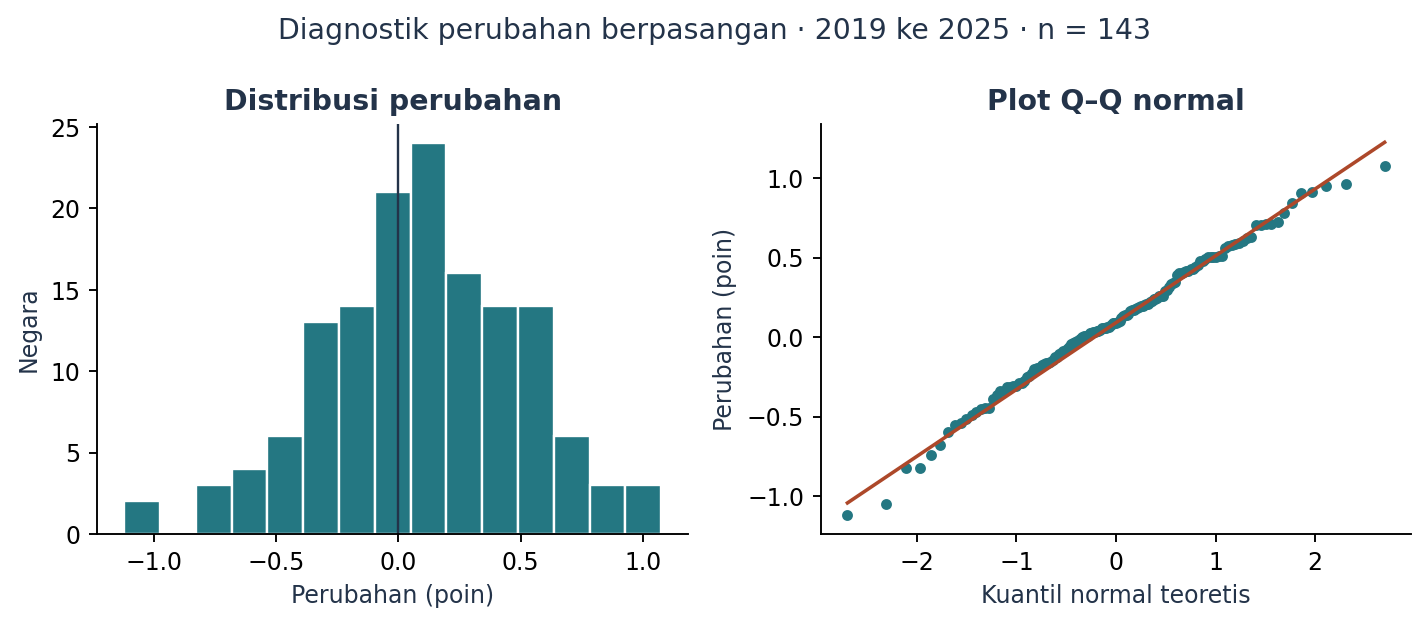

In [5]:
def lag_one(series):
    on_calendar = series.reindex(range(2011, 2026))
    pairs = pd.concat([on_calendar, on_calendar.shift(1)], axis=1).dropna()
    return {'adjacent_pairs': len(pairs), 'lag1_r': pairs.iloc[:, 0].corr(pairs.iloc[:, 1])}

diagnostics = pd.DataFrame({name: lag_one(trend[name])
                            for name in ['available_mean', 'balanced_mean']}).T
diagnostics.to_csv(OUT / 'temporal_diagnostics.csv')
display(diagnostics)

from statistics import NormalDist
d = main.delta.sort_values().to_numpy()
probs = (np.arange(len(d)) + .5) / len(d)
theoretical = np.array([NormalDist().inv_cdf(p) for p in probs])
slope = (np.quantile(d, .75) - np.quantile(d, .25)) / (2 * NormalDist().inv_cdf(.75))
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.7))
axes[0].hist(d, bins=15, color='#247782', edgecolor='white')
axes[0].axvline(0, color='#233349', lw=1)
axes[0].set(title='Distribusi perubahan', xlabel='Perubahan (poin)', ylabel='Negara')
axes[1].scatter(theoretical, d, s=13, color='#247782')
axes[1].plot(theoretical, np.median(d) + slope * theoretical, color='#ad482a')
axes[1].set(title='Plot Q–Q normal', xlabel='Kuantil normal teoretis', ylabel='Perubahan (poin)')
fig.suptitle(f'Diagnostik perubahan berpasangan · 2019 ke 2025 · n = {len(d)}')
publish(fig, '05_change_diagnostics.png')

## 5. Dekomposisi resmi WHR

Enam kontribusi dihitung oleh WHR menggunakan model dan tolok ukur Dystopia. Segmen ketujuh menggabungkan prediksi Dystopia dengan residual negara. Semua segmen dinyatakan dalam poin skor. Jumlah segmen hampir sama dengan skor karena pembulatan. Analisis ini memeriksa identitas dan membandingkan komponen terbitan. Hubungan aritmetis tersebut mendasari keputusan untuk menghapus regresi ulang dan korelasi sebagai klaim pengaruh faktor.

Galat absolut maksimum: 0.003 poin. Data komponen 2025 tidak lengkap: Tajikistan, State of Palestine.


,mean,median,min,max
c_gdp,1.539,1.582,0.000,2.167
c_support,1.202,1.286,0.000,1.720
c_health,0.615,0.606,0.000,1.238
c_freedom,0.883,0.914,0.000,1.147
c_generosity,0.107,0.107,0.000,0.295
c_corruption,0.147,0.115,0.000,0.512
dystopia_residual,1.163,1.164,-0.295,2.701


,score,c_gdp,c_support,c_health,c_freedom,c_generosity,c_corruption,dystopia_residual,reconstructed_score
country,,,,,,,,,
Finland,7.764,1.915,1.638,0.939,1.105,0.093,0.491,1.582,7.763
Indonesia,5.617,1.512,1.229,0.485,1.043,0.295,0.033,1.020,5.617
Afghanistan,1.446,0.921,0.000,0.176,0.000,0.079,0.131,0.139,1.446


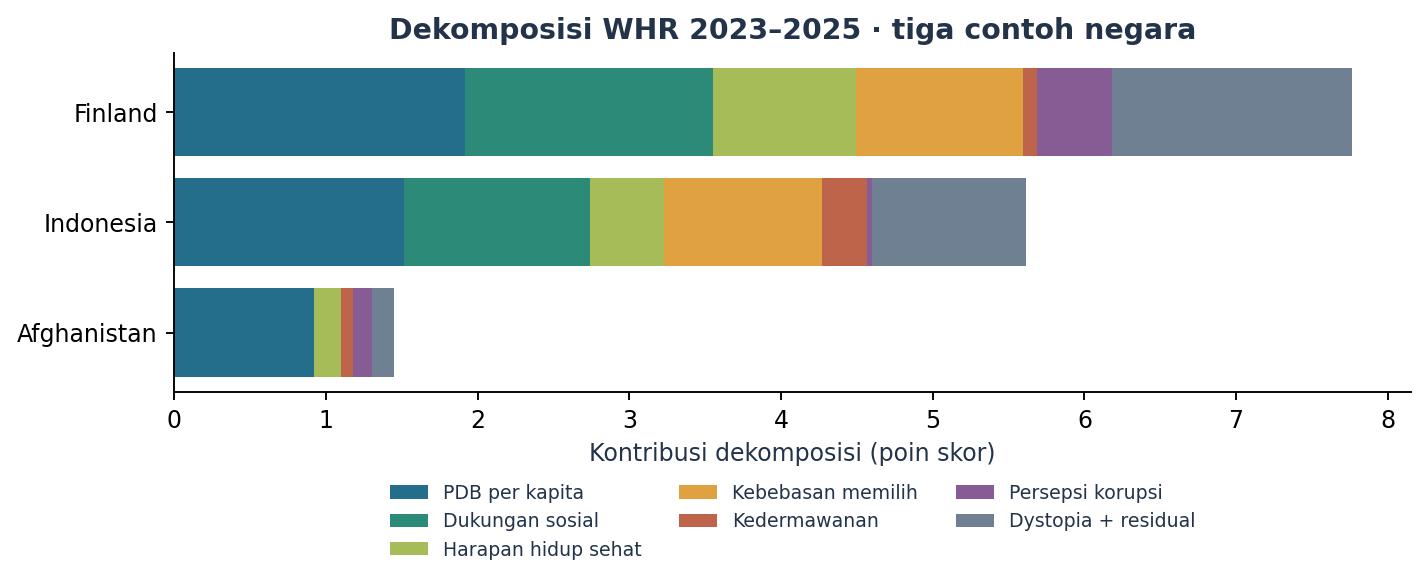

In [6]:
complete = data[data.complete_decomposition].copy()
complete['reconstructed_score'] = complete[COMP].sum(axis=1)
complete['reconstruction_error'] = (complete['score'] - complete['reconstructed_score']).round(9)
max_error = complete.reconstruction_error.abs().max()
assert len(complete) == 1013 and max_error <= .004  # 8 angka, masing-masing dibulatkan hingga .001
decomp_2025 = complete[complete.year.eq(2025)]
assert len(decomp_2025) == 145
excluded = latest.loc[~latest.complete_decomposition, 'country'].tolist()
complete[['year', 'country', 'score', 'reconstructed_score', 'reconstruction_error']].to_csv(
    OUT / 'decomposition_validation.csv', index=False)
component_summary = decomp_2025[COMP].agg(['mean', 'median', 'min', 'max']).T
component_summary.to_csv(OUT / 'component_summary_2025.csv')
decomp_focus = decomp_2025.set_index('country').loc[['Finland', 'Indonesia', 'Afghanistan']]
decomp_focus[['score', *COMP, 'reconstructed_score']].to_csv(OUT / 'decomposition_examples.csv')
display(component_summary)
display(decomp_focus[['score', *COMP, 'reconstructed_score']])
print(f'Galat absolut maksimum: {max_error:.3f} poin. Data komponen 2025 tidak lengkap: {", ".join(excluded)}.')

fig, ax = plt.subplots(figsize=(8.5, 3.7))
labels = decomp_focus.index
left = np.zeros(len(labels))
colors = ['#246d8b', '#2b8b78', '#a6bc59', '#e0a141', '#bd644b', '#875c94', '#708093']
for col, label, color in zip(COMP, LABELS, colors):
    values = decomp_focus[col].to_numpy()
    ax.barh(labels, values, left=np.where(values < 0, 0, left), label=label, color=color)
    left += np.maximum(values, 0)
ax.invert_yaxis()
ax.set(xlabel='Kontribusi dekomposisi (poin skor)',
       title='Dekomposisi WHR 2023–2025 · tiga contoh negara')
ax.legend(ncol=3, frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(.5, -.22))
publish(fig, '06_decomposition.png')

## 6. Ringkasan untuk pelaporan

Sel terakhir menyimpan angka utama untuk pemeriksaan silang laporan dan README. Indonesia dipakai sebagai contoh membaca skor, interval dan peringkat bersama. Perubahan peringkat bergantung pada skor negara lain dan komposisi daftar. Perubahan skor berpasangan memiliki makna langsung dalam satuan poin.

Analisis menggunakan agregat negara dan tidak mendukung kesimpulan tentang individu. Batas periode dan pilihan panel memengaruhi hasil. Enam komponen WHR digunakan dalam lingkup dekomposisi yang diterbitkan. Analisis determinan baru memerlukan indikator mentah yang cocok pada tingkat negara dan periode serta rancangan terpisah.

In [7]:
id_rows = data[data.country.eq('Indonesia')].set_index('year')
metrics = {
    'snapshot': snapshot_summary,
    'balanced_n': len(balanced),
    'mean_first': trend.loc[2011].to_dict(),
    'mean_latest': trend.loc[2025].to_dict(),
    'main_change': change_stats(main),
    'sensitivity': comparisons,
    'indonesia': {str(y): id_rows.loc[y, ['rank', 'score', 'ci_lower', 'ci_upper']].to_dict()
                  for y in [2019, 2022, 2024, 2025]},
    'indonesia_change': main.loc['Indonesia', 'delta'],
    'largest_gains': main.delta.head(4).to_dict(),
    'largest_losses': main.delta.tail(4).to_dict(),
    'max_reconstruction_error': max_error,
    'complete_decomposition_2025': len(decomp_2025),
    'excluded_decomposition_2025': excluded,
    'sha256_official_workbook': EXPECTED_HASH,
}
assert np.isclose(main.delta.mean(), main.end_score.mean() - main.start_score.mean())
assert len(main) >= len(balanced)
assert all(item['n'] == item['increased'] + item['decreased'] + item['same_at_precision']
           for item in comparisons.values())
(OUT / 'metrics.json').write_text(json.dumps(metrics, indent=2, ensure_ascii=False),
                                 encoding='utf-8')
print(f'2023–2025: rerata {s.mean():.3f}, median {s.median():.3f}, rentang {s.max()-s.min():.3f} poin.')
print(f'2019 ke 2025: {len(main)} negara berpasangan, rerata perubahan {main.delta.mean():+.3f} poin.')
print(f'Indonesia: peringkat {int(id_rows.loc[2025, "rank"])}, skor {id_rows.loc[2025, "score"]:.3f}, '
      f'perubahan {main.loc["Indonesia", "delta"]:+.3f} poin dari label 2019.')
print('Semua pemeriksaan data dan konsistensi hasil lulus.')

2023–2025: rerata 5.650, median 5.937, rentang 6.318 poin.
2019 ke 2025: 143 negara berpasangan, rerata perubahan +0.102 poin.
Indonesia: peringkat 87, skor 5.617, perubahan +0.331 poin dari label 2019.
Semua pemeriksaan data dan konsistensi hasil lulus.
